In [4]:
import pandas as pd

trips = pd.read_parquet("Boarding-Confidence-Data/trips.parquet")

service_dates = pd.to_datetime(trips["service_date"])

in_training_period = service_dates.between("2023-01-01", "2023-08-28")
train = trips.loc[in_training_period].copy()

print("Training departures:", len(train))
train[["trip_id", "scheduled_departure", "seats", "total_capacity", "peak_onboard"]].head()

Training departures: 23100


,trip_id,scheduled_departure,seats,total_capacity,peak_onboard
0,20230101-0-01,2023-01-01 07:00:00+05:30,36,55,55
1,20230101-0-02,2023-01-01 07:20:00+05:30,36,55,50
2,20230101-0-03,2023-01-01 07:40:00+05:30,42,64,49
3,20230101-0-04,2023-01-01 08:00:00+05:30,36,55,41
4,20230101-0-05,2023-01-01 08:20:00+05:30,36,55,46


In [5]:
print("Duplicate trip IDs:", train["trip_id"].duplicated().sum())
print("Missing peak loads:", train["peak_onboard"].isna().sum())
print("Negative peak loads:", train["peak_onboard"].lt(0).sum())
print("Peak loads above total capacity:",
      train["peak_onboard"].gt(train["total_capacity"]).sum())

Duplicate trip IDs: 0
Missing peak loads: 0
Negative peak loads: 0
Peak loads above total capacity: 0



How much more crowded are peak departures?

In [8]:
train["above_seats"] = train["peak_onboard"] > train["seats"]

crowding = train.groupby("peak").agg(
    departures=("trip_id", "size"),
    median_peak_load=("peak_onboard", "median"),
    share_above_seats=("above_seats", "mean"),
)
crowding["percent_above_seats"] = 100 * crowding["share_above_seats"]
crowding[["departures", "median_peak_load", "percent_above_seats"]].round(1)

,departures,median_peak_load,percent_above_seats
peak,,,
False,14550,43.0,70.5
True,8550,52.0,89.3


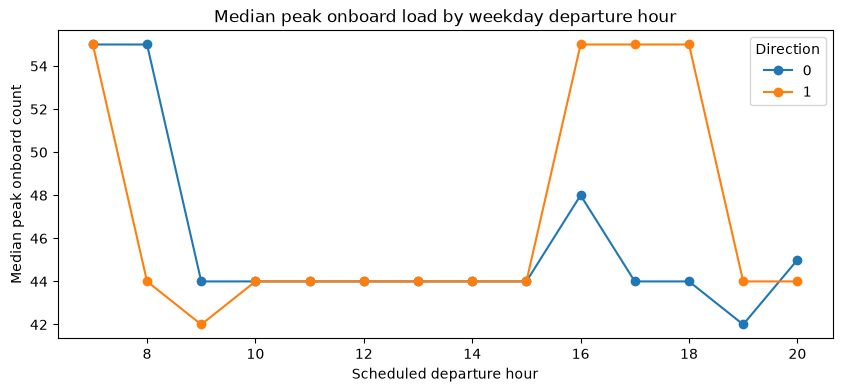

In [9]:
import matplotlib.pyplot as plt

train["departure_hour"] = pd.to_datetime(train["scheduled_departure"]).dt.hour
weekday_trips = train.loc[train["weekday"] < 5]

hourly_load = (
    weekday_trips.groupby(["departure_hour", "direction"])["peak_onboard"]
    .median()
    .unstack("direction")
)

ax = hourly_load.plot(marker="o", figsize=(10, 4))
ax.set_title("Median peak onboard load by weekday departure hour")
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("Median peak onboard count")
ax.legend(title="Direction")
plt.show()

In the simulated weekday training data, the busiest departure hours differ by direction. Direction 0 reaches a median peak onboard load of 55 passengers** for departures in the 7 a.m. and 8 a.m. hours. Direction 1 also reaches 55 at 7 a.m., then returns to that level for departures in the 4 p.m., 5 p.m. and 6 p.m. hours**. From 10 a.m. through 3 p.m. Both directions have a median peak load of 44 passengers. This pattern supports grouping the historical baseline by both departure hour and direction, so it can capture differences such as the 5 p.m. hour, when the median is 55 in Direction 1 and 44 in Direction 0.

### Passengers left waiting at stops 2 and 3

This table compares stops 2 and 3 on the same 23,100 simulated training departures. `True` means at least one passenger was still waiting after the bus served the stop. `False` means nobody was left waiting.

On 14,733 departures, nobody was left waiting at either stop. On 6,412 departures, passengers were left waiting only at stop 3, while the reverse occurred on just one departure. On 1,954 departures, passengers were left waiting at both stops.

In this simulation, passengers were much more often left waiting at stop 3 than at stop 2. That makes stop 2 worth considering as an upstream boarding option. The next analysis checks whether a passenger could walk there before the bus arrived and still find room to board.

In [11]:
stop_events = pd.read_parquet(
    "Boarding-Confidence-Data/stop_events.parquet"
)

training_stops = stop_events.loc[
    stop_events["trip_id"].isin(train["trip_id"])
    & stop_events["stop_sequence"].isin([2, 3])
]

queues = training_stops.pivot(
    index="trip_id",
    columns="stop_sequence",
    values="queue_after",
)

boarding_summary = pd.crosstab(
    queues[2].gt(0).rename("Stop 2 had riders left waiting"),
    queues[3].gt(0).rename("Stop 3 had riders left waiting"),
)

boarding_summary

Stop 3 had riders left waiting,False,True
Stop 2 had riders left waiting,,
False,14733,6412
True,1,1954


### Boarding the same bus by walking or staying

This table compares two choices for a passenger at stop 3 across 23,100 simulated training departures. The passenger decides seven minutes before the bus is scheduled to reach stop 3 and can either stay there or walk four minutes upstream to stop 2. An option counts as successful if the passenger reaches the stop by the bus’s simulated arrival and there is room after the existing queue boards.

Walking was the only successful option on 4,186 departures (18.1%), while staying was the only successful option on 6,174 (26.7%). Both options worked on 8,219 departures (35.6%), and neither worked on 4,521 (19.6%).

Staying worked more often overall under these assumptions, but walking helped in a substantial share of cases. This gives us a benchmark for a recommendation model. Can it identify when walking improves the chance of boarding the same bus compared with always staying? A separate analysis would need to follow later departures to compare total waiting time.

In [12]:
comparison = training_stops.copy()

comparison["space_left"] = (
    comparison["total_capacity"] - comparison["onboard_departure"]
)

by_stop = comparison.pivot(
    index="trip_id",
    columns="stop_sequence",
    values=["planned_stop_time", "observed_arrival", "space_left"],
)

decision_time = by_stop["planned_stop_time"][3] - pd.Timedelta(minutes=7)
arrival_if_walking = decision_time + pd.Timedelta(minutes=4)

walk_can_board = (
    arrival_if_walking.le(by_stop["observed_arrival"][2])
    & by_stop["space_left"][2].gt(0)
)

stay_can_board = (
    decision_time.le(by_stop["observed_arrival"][3])
    & by_stop["space_left"][3].gt(0)
)

pd.crosstab(
    walk_can_board.rename("Can board if walking"),
    stay_can_board.rename("Can board if staying"),
)

Can board if staying,False,True
Can board if walking,,
False,4521,6174
True,4186,8219


### How walking time affects the chance of boarding

This analysis compares 2-, 4-, and 6-minute walks from stop 3 to stop 2 across 23,100 simulated training departures. In each scenario, the passenger decides seven minutes before the bus is scheduled to reach stop 3. Walking works if the passenger reaches stop 2 by the bus’s simulated arrival and there is room after the existing queue boards.

As walking time increases from two to six minutes, the number of departures the passenger reaches too late at stop 2 rises from 126 to 20,229. Departures where walking is the only successful option fall from 6,567 to 925, while departures where staying is the only successful option rise from 96 to 12,945. The preferred choice depends heavily on walking time. These results measure whether the passenger catches the same bus under the simulated conditions.

In [13]:
results = []

for walk_minutes in [2, 4, 6]:
    arrival_if_walking = decision_time + pd.Timedelta(minutes=walk_minutes)
    reach_in_time = arrival_if_walking <= by_stop["observed_arrival"][2]
    space_available = by_stop["space_left"][2] > 0
    walk_can_board = reach_in_time & space_available

    results.append({
        "walk_minutes": walk_minutes,
        "missed_upstream_bus": (~reach_in_time).sum(),
        "walking_only": (walk_can_board & ~stay_can_board).sum(),
        "staying_only": (stay_can_board & ~walk_can_board).sum(),
    })

pd.DataFrame(results)

,walk_minutes,missed_upstream_bus,walking_only,staying_only
0,2,126,6567,96
1,4,9163,4186,6174
2,6,20229,925,12945


### When passengers get a seat

This analysis covers 1,775,728 simulated passengers who boarded a training departure. It subtracts each passenger’s boarding stop sequence from the sequence of the first stop where they got a seat. A difference of zero means they sat down when they boarded. A positive difference means they got a seat later. A missing first seated stop means they stood for the entire ride.

69.7% got a seat at boarding, 16.4% got one at a later stop, and 13.9% stood for the entire ride. Among passengers who boarded standing, about 54% eventually got a seat. These are simulated outcomes, so the percentages reflect the simulator’s seating assumptions.

In [14]:
passengers = pd.read_parquet(
    "Boarding-Confidence-Data/passengers.parquet",
    columns=["boarded_trip_id", "origin_sequence", "first_seated_sequence"],
)

boarded = passengers.loc[
    passengers["boarded_trip_id"].isin(train["trip_id"])
]

stops_until_seated = (
    boarded["first_seated_sequence"] - boarded["origin_sequence"]
)

counts = pd.Series({
    "Seated at boarding": stops_until_seated.eq(0).sum(),
    "Seated at a later stop": stops_until_seated.gt(0).sum(),
    "Stood for the whole ride": stops_until_seated.isna().sum(),
})

seating_summary = counts.to_frame("passengers")
seating_summary["percent"] = (100 * counts / len(boarded)).round(1)
seating_summary

,passengers,percent
Seated at boarding,1237875,69.7
Seated at a later stop,291000,16.4
Stood for the whole ride,246853,13.9


### Preparing a chronological validation period

The training period contains 23,100 departures from January 1 through August 28, 2023. Validation contains 4,616 later departures from August 29 through October 15. The baseline uses the scheduled departure hour and whether the trip runs on a weekday or weekend. The timestamp check confirms that every training load was available by the first validation forecast.

In [15]:
service_dates = pd.to_datetime(trips["service_date"])
validation = trips.loc[
    service_dates.between("2023-08-29", "2023-10-15")
].copy()

for frame in (train, validation):
    frame["departure_hour"] = pd.to_datetime(
        frame["scheduled_departure"]
    ).dt.hour
    frame["is_weekend"] = frame["weekday"].ge(5)

assert train["load_available_at"].max() <= validation["forecast_at"].min()

print("Training departures:", len(train))
print("Validation departures:", len(validation))

Training departures: 23100
Validation departures: 4616


### Historical route and time baseline

For each validation departure, the baseline looks up the median training load for the same route, direction, departure hour and weekday or weekend category. If a group is absent from training, it uses the overall training median. For the first validation trip, the baseline predicts 55 passengers and the simulated peak load is 44, an overestimate of 11 passengers.

In [16]:
group_columns = [
    "route_id", "direction", "departure_hour", "is_weekend"
]

historical_loads = (
    train.groupby(group_columns, as_index=False)["peak_onboard"]
    .median()
    .rename(columns={"peak_onboard": "historical_median"})
)

baseline_results = validation.merge(
    historical_loads,
    on=group_columns,
    how="left",
    validate="many_to_one",
)

baseline_results["baseline_prediction"] = (
    baseline_results["historical_median"]
    .fillna(train["peak_onboard"].median())
)

baseline_results[
    ["scheduled_departure", "peak_onboard", "baseline_prediction"]
].head()


,scheduled_departure,peak_onboard,baseline_prediction
0,2023-08-29 07:00:00+05:30,44,55.0
1,2023-08-29 07:12:00+05:30,55,55.0
2,2023-08-29 07:24:00+05:30,55,55.0
3,2023-08-29 07:36:00+05:30,39,55.0
4,2023-08-29 07:48:00+05:30,53,55.0


### Baseline validation results

The historical baseline achieved 8.17 passengers MAE, 10.56 passengers RMSE and 20.65% WAPE on validation. MAE is the average size of a prediction error. RMSE gives larger misses more weight. WAPE expresses the total absolute error as a percentage of the total observed passenger load. These scores give us a reference for evaluating the candidate models on the same departures.

In [17]:
error = baseline_results["baseline_prediction"] - baseline_results["peak_onboard"]
absolute_error = error.abs()

mae = absolute_error.mean()
rmse = error.pow(2).mean() ** 0.5
wape = 100 * absolute_error.sum() / baseline_results["peak_onboard"].sum()

print(f"MAE:  {mae:.2f} passengers")
print(f"RMSE: {rmse:.2f} passengers")
print(f"WAPE: {wape:.2f}%")

MAE:  8.17 passengers
RMSE: 10.56 passengers
WAPE: 20.65%


### Where the historical baseline misses

This table breaks down validation errors by direction and service period. Because `error` is calculated as prediction minus actual load, a positive mean error indicates that the baseline overpredicts on average.

Direction 1 during peak service had the highest MAE (8.89 passengers), the highest RMSE (11.99 passengers), and the largest average overprediction (6.93 passengers). Direction 1 off-peak had the highest WAPE (21.83%). WAPE scales the absolute error by the total actual load, so the group with the largest errors in passengers can differ from the group with the largest percentage error. The dataset represents one simulated route, so this breakdown compares directions within that route.

In [18]:
scored = baseline_results.copy()

scored["error"] = scored["baseline_prediction"] - scored["peak_onboard"]
scored["absolute_error"] = scored["error"].abs()
scored["squared_error"] = scored["error"].pow(2)
scored["period"] = scored["peak"].map({True: "Peak", False: "Off-peak"})

breakdown = scored.groupby(["direction", "period"]).agg(
    departures=("trip_id", "size"),
    mae=("absolute_error", "mean"),
    mean_squared_error=("squared_error", "mean"),
    total_absolute_error=("absolute_error", "sum"),
    total_actual_load=("peak_onboard", "sum"),
    mean_error=("error", "mean"),
)

breakdown["rmse"] = breakdown["mean_squared_error"] ** 0.5
actual_load = breakdown["total_actual_load"]
breakdown["wape_pct"] = (
    100 * breakdown["total_absolute_error"] / actual_load.where(actual_load > 0)
)

breakdown[["departures", "mae", "rmse", "wape_pct", "mean_error"]].round(2)

departures   mae   rmse  wape_pct  mean_error
direction period                                                 
0         Off-peak        1458  7.79   9.91     21.40        4.89
          Peak             850  8.40  11.11     19.23        5.53
1         Off-peak        1458  7.99   9.94     21.83        4.56
          Peak             850  8.89  11.99     19.38        6.93

### Preparing features for the passenger load model

The model predicts `peak_onboard`, the highest number of passengers aboard at the same time during a scheduled departure. `X` contains the information the model receives, and `y` contains the peak load it learns to predict.

The seven inputs describe the scheduled trip and its planned capacity. `departure_minute` gives the number of minutes since midnight. For example, 7:00 a.m. becomes 420. The timestamp checks confirm that each forecast is issued 30 minutes before departure and the schedule and capacity are already known at that point. Observed passenger counts and queues from the trip are reserved for evaluating predictions. The dataset covers a single route, so the inputs include direction and the model is evaluated on that route.

The training feature table has 23,100 rows and seven columns. The validation feature table has 4,616 rows and the same seven columns.

In [19]:
for frame in (train, validation):
    departure = pd.to_datetime(frame["scheduled_departure"])
    frame["departure_minute"] = departure.dt.hour * 60 + departure.dt.minute

    assert (departure - frame["forecast_at"]).eq(
        pd.Timedelta(minutes=30)
    ).all()
    assert frame["schedule_and_capacity_known_at"].le(
        frame["forecast_at"]
    ).all()

feature_columns = [
    "departure_minute",
    "weekday",
    "season",
    "direction",
    "peak",
    "seats",
    "total_capacity",
]

X_train = train[feature_columns].copy()
y_train = train["peak_onboard"].copy()

X_validation = validation[feature_columns].copy()
y_validation = validation["peak_onboard"].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
X_train.head()

Training features: (23100, 7)
Validation features: (4616, 7)


,departure_minute,weekday,season,direction,peak,seats,total_capacity
0,420,6,0,0,False,36,55
1,440,6,0,0,False,36,55
2,460,6,0,0,False,42,64
3,480,6,0,0,False,36,55
4,500,6,0,0,False,36,55
